# 00 · Transaction costs measured from trades and quotes

`adaptation-matrix` downloads days of Massive trades and NBBO quotes, matches every trade to the
quote in force, keeps compact tables and deletes the ticks (a smaller Massive plan cannot
download them again). Design: `docs/decisions/0016-adaptation-matrix.md`.

1. what is stored
2. costs by company size on one day
3. effective spreads against dollar volume, and the backtester's current rule
4. spreads through the day
5. the close against the quote
6. 2005 against 2026, and a data-quality flag
7. one trade, decomposed

All measures are **half-spreads in basis points of the midpoint** (a round trip costs twice).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from adaptation_matrix import AdaptationMatrix
from subspace_probe import style
from vinculum import Vinculum

style()
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
pl.Config.set_float_precision(2)
m = AdaptationMatrix()
v = Vinculum()
DAY, OLD = "2026-11-10", "2005-06-15"
SIZES = ["large", "mid", "small", "micro"]                 # vinculum's size buckets, in this order
COLORS = dict(zip(SIZES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))  # fixed categorical order
m.status()

{'root': '/Users/yuriturygin/market_data/adaptation_matrix',
 'days_done': 2,
 'by_set': {'stored': 2},
 'failed': [],
 'first': datetime.date(2005, 6, 15),
 'last': datetime.date(2026, 11, 10),
 'store_gb': 1.3,
 'max_store_gb': 480.0}

## 1 · What is stored

One row per measured day in `days()`: the set it belongs to (`recent`, `sample`, `event`, or
`stored` for a day measured from ticks already in the Massive store), rows and size of the three
tables, and how long downloading, converting and measuring took.

In [2]:
m.days().select("day", "status", "set", "interpolated", "daily_rows", "trades_rows", "gb", "measure_s")

day,status,set,interpolated,daily_rows,trades_rows,gb,measure_s
date,str,str,bool,i64,i64,f64,f64
2005-06-15,"""done""","""stored""",true,7862,4517780,0.15,8.90
2026-11-10,"""done""","""stored""",false,13181,64297714,1.15,155.50


## 2 · Costs by company size

`daily()` has one row per ticker. Joined to vinculum's size buckets (rank on the previous month
end) and kept to names with at least 50 trades and under 20% of trades outside the quote.
Effective spreads are well below quoted ones: trades happen when the spread is narrow, and many
get price improvement inside it. Realized + impact = effective.

In [3]:
def sized(day):
    d = m.daily(start=day, end=day)
    r = v.ranks(v.rank_date(pl.Series([day]).str.to_date()[0], "monthly"))
    return (d.join(r.select("security_id", "size"), on="security_id", how="inner")
            .filter((pl.col("n_trades") >= 50) & (pl.col("outside_share") < 0.2)))

d = sized(DAY)
(d.group_by("size").agg(pl.len().alias("names"), pl.col("qhs_bps").median().alias("quoted"),
                        pl.col("eff_bps").median().alias("effective"), pl.col("rs_5m_bps").median().alias("realized_5m"),
                        pl.col("pi_5m_bps").median().alias("impact_5m"), pl.col("eff_trf_bps").median().alias("eff_off_exchange"),
                        pl.col("eff_lit_bps").median().alias("eff_lit"))
 .sort(pl.col("size").replace_strict({s: i for i, s in enumerate(SIZES)})))

size,names,quoted,effective,realized_5m,impact_5m,eff_off_exchange,eff_lit
str,u32,f64,f64,f64,f64,f64,f64
"""large""",200,3.40,1.25,0.33,0.89,1.15,1.32
"""mid""",798,7.36,2.39,0.60,1.75,2.16,2.53
"""small""",1991,18.97,6.44,1.48,4.79,6.07,6.69
"""micro""",1752,112.35,55.43,20.19,23.12,54.55,52.68


## 3 · Effective spread against dollar volume

The daily backtester (unimatrix-zero) charges a half-spread of 30 bp × (ADV in $M)^-0.5 by
default. Here it is against what was measured on one day, with that day's dollar volume standing
in for ADV. The calibration (decision 0016, phase 2) fits this relation on hundreds of days.

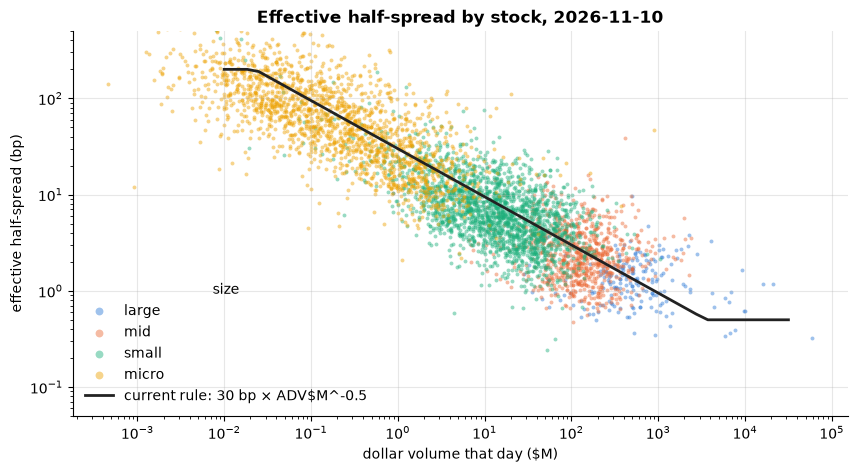

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
for s in SIZES:
    x = d.filter(pl.col("size") == s)
    ax.scatter(x["dollar_volume"] / 1e6, x["eff_bps"], s=8, alpha=0.45, color=COLORS[s], label=s, linewidths=0)
grid = np.logspace(-2, 4.5, 50)
ax.plot(grid, np.clip(30 * grid ** -0.5, 0.5, 200), color="#222", lw=2, label="current rule: 30 bp × ADV$M^-0.5")
ax.set(xscale="log", yscale="log", xlabel="dollar volume that day ($M)", ylabel="effective half-spread (bp)",
       title=f"Effective half-spread by stock, {DAY}", ylim=(0.05, 500))
ax.legend(title="size", markerscale=2)
plt.show()

## 4 · Spreads through the day

`buckets()` aggregates the minute table into 15-minute buckets with the same weights (time for
quotes, dollar volume for trades), so buckets average exactly to the day. The median quoted
half-spread across names in each bucket, by size: wide at the open, narrowing through the morning,
tightest before the close. tactical-cube now assumes 3× / 2× / 1.5× in the first 5 / 15 / 30
minutes.

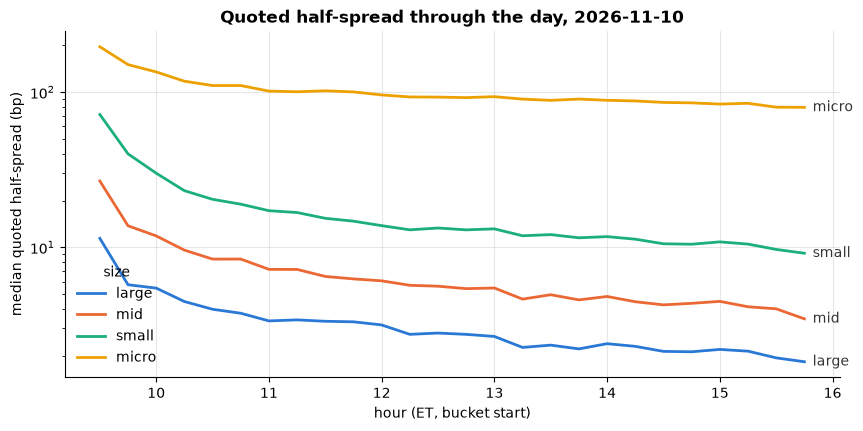

size,first_15m,day,multiple
str,f64,f64,f64
"""large""",11.42,3.40,3.36
"""mid""",26.72,7.36,3.63
"""small""",71.66,18.97,3.78
"""micro""",195.75,112.35,1.74


In [5]:
b = m.buckets(start=DAY, end=DAY, minutes=15).join(d.select("ticker", "size"), on="ticker")
prof = (b.group_by("size", "bucket").agg(pl.col("qhs_bps").median()).sort("bucket"))
fig, ax = plt.subplots(figsize=(10, 4.5))
for s in SIZES:
    x = prof.filter(pl.col("size") == s)
    ax.plot(x["bucket"] * 15 / 60 + 9.5, x["qhs_bps"], lw=2, color=COLORS[s], label=s)
    ax.annotate(s, (x["bucket"][-1] * 15 / 60 + 9.5, x["qhs_bps"][-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color="#333")
ax.set(yscale="log", xlabel="hour (ET, bucket start)", ylabel="median quoted half-spread (bp)",
       title=f"Quoted half-spread through the day, {DAY}")
ax.legend(title="size")
plt.show()
day_avg = d.group_by("size").agg(pl.col("qhs_bps").median().alias("day"))
first = prof.filter(pl.col("bucket") == 0).select("size", pl.col("qhs_bps").alias("first_15m"))
first.join(day_avg, on="size").with_columns((pl.col("first_15m") / pl.col("day")).alias("multiple"))

## 5 · The close against the quote

A market-on-close order gets the official close. `close_vs_mid_bps` compares it with the
midpoint just before the close. If the close typically sits half a spread from the mid, a close
fill costs about the same as crossing the spread; if it sits at the mid, it costs nothing beyond
impact. The daily backtester charges the half-spread, tactical-cube nothing.

In [6]:
(d.group_by("size").agg(pl.len().alias("names"),
                        pl.col("qhs_preclose_bps").median().alias("half_spread_before_close"),
                        pl.col("close_vs_mid_bps").abs().median().alias("abs_close_vs_mid"),
                        pl.col("close_vs_mid_bps").median().alias("close_vs_mid"),
                        (pl.col("close_auction_volume") * pl.col("official_close") / pl.col("dollar_volume")).median()
                        .alias("auction_vs_continuous_volume"))
 .sort(pl.col("size").replace_strict({s: i for i, s in enumerate(SIZES)})))

size,names,half_spread_before_close,abs_close_vs_mid,close_vs_mid,auction_vs_continuous_volume
str,u32,f64,f64,f64,f64
"""large""",200,1.33,1.48,0.31,0.22
"""mid""",798,2.28,2.18,-0.54,0.24
"""small""",1991,6.26,5.51,0.00,0.19
"""micro""",1752,68.98,52.22,-21.67,0.03


## 6 · 2005 against 2026, and a data-quality flag

vinculum has no market caps before SEC share counts (about 2009), so here both days are bucketed
by the day's dollar volume. 2005 quote timestamps are whole seconds, so trades are matched on
Holden-Jacobsen interpolated time (`interpolated` in `days()`). `outside_share` is the share of
matched trades outside the quote: about 5% is normal, SPY's 28% in 2005 says its quotes that year
were not a full NBBO, so such ticker-days are filtered, never fixed.

In [7]:
def by_dv(day):
    x = m.daily(start=day, end=day).filter(pl.col("n_trades") >= 50)
    q = pl.col("dollar_volume").rank() / pl.len()
    dv = (pl.when(q > 0.99).then(pl.lit("5 top 1%")).when(q > 0.95).then(pl.lit("4 p95-99"))
          .when(q > 0.8).then(pl.lit("3 p80-95")).when(q > 0.5).then(pl.lit("2 p50-80")).otherwise(pl.lit("1 <p50")))
    return (x.with_columns(dv.alias("dv"))
            .group_by("dv").agg(pl.len().alias("names"), pl.col("eff_bps").median().alias(f"eff_{day[:4]}"),
                                pl.col("outside_share").median().alias(f"outside_{day[:4]}")).sort("dv"))

display(by_dv(OLD).join(by_dv(DAY), on="dv", suffix="_2026"))
m.daily(["SPY", "AAPL", "MSFT", "GE"]).select("date", "ticker", "qhs_bps", "eff_bps", "outside_share").sort("ticker", "date")

dv,names,eff_2005,outside_2005,names_2026,eff_2026,outside_2026
str,u32,f64,f64,u32,f64,f64
"""1 <p50""",2373,19.65,0.05,5037,15.72,0.00
"""2 p50-80""",1423,7.42,0.12,3023,5.25,0.01
"""3 p80-95""",712,4.57,0.11,1511,2.39,0.03
"""4 p95-99""",190,2.72,0.12,403,1.58,0.03
"""5 top 1%""",48,2.33,0.13,101,0.84,0.03


date,ticker,qhs_bps,eff_bps,outside_share
date,str,f64,f64,f64
2005-06-15,"""AAPL""",1.11,2.07,0.21
2026-11-10,"""AAPL""",0.72,0.36,0.03
2005-06-15,"""GE""",1.48,1.96,0.08
2026-11-10,"""GE""",3.43,1.23,0.04
2005-06-15,"""MSFT""",1.47,1.63,0.06
2026-11-10,"""MSFT""",1.21,0.62,0.04
2005-06-15,"""SPY""",0.39,1.20,0.28
2026-11-10,"""SPY""",0.15,0.10,0.05


## 7 · One trade, decomposed

`trades()` keeps every trade of the largest 1,000 companies and 100 ETFs with the NBBO in force,
its sign and the midpoints 1 and 5 minutes later. Off-exchange prints (exchange 4) are matched on
their execution time, not the SIP time, which arrives late.

In [8]:
t = m.trades("AAPL", DAY, DAY).filter(pl.col("kind") == 0)
mid = (pl.col("bid") + pl.col("ask")) / 2
big = (t.sort("size", descending=True).head(5)
       .select("t", "price", "size", "exchange", "bid", "ask", "sign",
               ((pl.col("price") - mid).abs() / mid * 1e4).alias("effective"),
               (pl.col("sign") * (pl.col("price") - pl.col("mid_5m")) / mid * 1e4).alias("realized_5m"),
               (pl.col("sign") * (pl.col("mid_5m") - mid) / mid * 1e4).alias("impact_5m")))
print(f"{t.height:,} continuous AAPL trades kept on {DAY}; the five largest:")
big

577,096 continuous AAPL trades kept on 2026-11-10; the five largest:


t,price,size,exchange,bid,ask,sign,effective,realized_5m,impact_5m
"datetime[ns, UTC]",f64,f64,i16,f64,f64,i8,f64,f64,f64
2026-11-10 14:59:16.267663303 UTC,348.25,140000.00,12,348.27,348.28,-1,0.72,4.74,-4.02
2026-11-10 15:06:17.797157856 UTC,348.81,80800.00,4,348.76,348.85,1,0.14,38.99,-38.85
2026-11-10 19:33:35.595026780 UTC,348.64,31584.00,4,348.61,348.64,1,0.43,-1.00,1.43
2026-11-10 19:23:11.757239 UTC,348.56,29625.00,4,348.55,348.58,-1,0.00,-9.04,9.04
2026-11-10 16:06:56.978 UTC,347.55,28436.00,4,347.50,347.60,-1,0.00,-3.31,3.31
